In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!python -m pip install pandas huggingface_hub

In [3]:

from huggingface_hub import hf_hub_download
from pathlib import Path
import shutil

REPO = "yadavsaurabh/indian-railways-runs"

TRAINS = [
    "66610",
     # kottayam exp
    # "16350",  # thiruvanthapuram
    "66320", # 5:40
    "16346",
    "16306",
    "12625",
    "16325"
]

output = Path("data/raw")
output.mkdir(parents=True, exist_ok=True)

for train in TRAINS:
    try:
        remote_path = f"trains/{train}.csv"

        downloaded = hf_hub_download(
            repo_id=REPO,
            repo_type="dataset",
            filename=remote_path,
        )

        destination = output / f"{train}.csv"
        shutil.copyfile(downloaded, destination)

        print(f"Downloaded: {destination}")

    except Exception as error:
        print(f"Failed for {train}: {error}")


c:\Desktop\luminar\Machine Learning\Trian Time Delay Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Failed for 66610: 404 Client Error. (Request ID: Root=1-6ae80e35-09298d287f2b29cc32c607bb;cc09e21c-8541-4ed0-a74a-98c2ca2428cb)

Entry Not Found for url: https://huggingface.co/datasets/yadavsaurabh/indian-railways-runs/resolve/main/trains/66610.csv.
Failed for 66320: 404 Client Error. (Request ID: Root=1-6ae80e35-264e9a6f2586b8bf0b603b5b;3a55c700-6bb7-47ff-9473-77662cefde2d)

Entry Not Found for url: https://huggingface.co/datasets/yadavsaurabh/indian-railways-runs/resolve/main/trains/66320.csv.
Downloaded: data\raw\16346.csv
Downloaded: data\raw\16306.csv
Downloaded: data\raw\12625.csv
Downloaded: data\raw\16325.csv


In [4]:

import pandas as pd
from pathlib import Path

files = list(Path("data/raw").glob("*.csv"))

if not files:
    raise FileNotFoundError("No train CSV files found.")

frames = []

for file in files:
    df = pd.read_csv(
        file,
        dtype={"train_no": "string"},
        low_memory=False
    )
    frames.append(df)

data = pd.concat(frames, ignore_index=True)

print("Total rows:", len(data))
print("Columns:", data.columns.tolist())
print("\nMissing values:")
print(data.isna().sum().sort_values(ascending=False))

Path("data").mkdir(exist_ok=True)
data.to_csv("data/railway_raw_combined.csv", index=False)

print("Saved: data/railway_raw_combined.csv")


Total rows: 173636
Columns: ['date', 'train_no', 'train_name', 'train_type', 'seq', 'station_code', 'halts_here', 'sch_arrival', 'sch_arrival_date', 'sch_departure', 'sch_departure_date', 'act_arrival', 'act_arrival_date', 'act_departure', 'act_departure_date', 'delay_arrival_min', 'delay_departure_min', 'platform', 'distance_km', 'lat', 'lng', 'departed', 'reported', 'reported_at']

Missing values:
delay_arrival_min      35700
delay_departure_min    25636
reported_at            22716
lng                    22700
lat                    22700
act_departure          21959
act_departure_date     21959
distance_km            12899
platform                8109
act_arrival             7978
act_arrival_date        7978
seq                     4921
train_no                   0
train_name                 0
date                       0
train_type                 0
sch_arrival                0
halts_here                 0
station_code               0
sch_departure_date         0
sch_departure    

# Load Data

In [5]:
df = data
df

,date,train_no,train_name,train_type,seq,station_code,halts_here,sch_arrival,sch_arrival_date,sch_departure,...,act_departure_date,delay_arrival_min,delay_departure_min,platform,distance_km,lat,lng,departed,reported,reported_at
0,2020-01-01,12625,KERALA SF EXP,SUF,0.0,TVC,1,11:15,01 Jan 2020,11:15,...,01 Jan 2020,NaN,9.0,3,0.000,8.486650,76.951720,1,1,2020-01-01T11:18:48.405627+05:30
1,2020-01-01,12625,KERALA SF EXP,SUF,11.0,VAK,1,11:49,01 Jan 2020,11:50,...,01 Jan 2020,16.0,22.0,1,40.468,8.737862,76.725536,1,1,2020-01-01T12:08:44.309807+05:30
2,2020-01-01,12625,KERALA SF EXP,SUF,17.0,QLN,1,12:22,01 Jan 2020,12:25,...,01 Jan 2020,8.0,17.0,2,64.206,8.884599,76.599089,1,1,2020-01-01T12:35:30.986416+05:30
3,2020-01-01,12625,KERALA SF EXP,SUF,23.0,KYJ,1,12:58,01 Jan 2020,13:00,...,01 Jan 2020,19.0,23.0,2,105.072,9.178853,76.513588,1,1,2020-01-01T13:19:06.401110+05:30
4,2020-01-01,12625,KERALA SF EXP,SUF,24.0,MVLK,1,13:09,01 Jan 2020,13:10,...,01 Jan 2020,21.0,28.0,1,112.878,9.237035,76.544363,1,1,2020-01-01T13:34:28.137609+05:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173631,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,191.0,KHED,1,11:20,02 Sep 2026,11:22,...,02 Sep 2026,0.0,0.0,1.0,1275.900,NaN,NaN,0,0,NaN
173632,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,202.0,ROHA,1,13:35,02 Sep 2026,13:40,...,02 Sep 2026,0.0,0.0,2.0,1374.300,NaN,NaN,0,0,NaN
173633,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,212.0,PNVL,1,14:52,02 Sep 2026,14:55,...,02 Sep 2026,0.0,0.0,5.0,1449.100,NaN,NaN,0,0,NaN
173634,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,223.0,TNA,1,15:47,02 Sep 2026,15:50,...,02 Sep 2026,0.0,0.0,8.0,1482.000,NaN,NaN,0,0,NaN


# Take Only Reported Columns

In [6]:
df = df[
    (df["reported"] == 1) & df['delay_arrival_min'].notna()
].copy()

In [7]:
df.shape

(128123, 24)

In [8]:
df.describe()

,seq,halts_here,delay_arrival_min,delay_departure_min,distance_km,lat,lng,departed,reported
count,128123.000000,128123.000000,128123.000000,117859.000000,128123.000000,128123.000000,128123.000000,128123.000000,128123.0
mean,120.548535,0.999820,33.687706,37.812233,715.873914,13.553051,76.514933,0.920116,1.0
std,122.711949,0.013397,70.757678,66.658615,799.388894,5.037541,1.602807,0.271115,0.0
min,0.000000,0.000000,2.000000,0.000000,0.000000,8.486650,72.891530,0.000000,1.0
25%,28.000000,1.000000,10.000000,14.000000,142.691000,10.227387,75.781966,1.000000,1.0
50%,72.000000,1.000000,20.000000,25.000000,357.996000,11.248985,76.354940,1.000000,1.0
75%,162.000000,1.000000,36.000000,41.000000,980.628000,15.004611,77.307408,1.000000,1.0
max,468.000000,1.000000,2924.000000,2025.000000,3024.861000,28.597075,80.619811,1.000000,1.0


In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 128123 entries, 1 to 173589
Data columns (total 24 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   date                 128123 non-null  str    
 1   train_no             128123 non-null  string 
 2   train_name           128123 non-null  str    
 3   train_type           128123 non-null  str    
 4   seq                  128123 non-null  float64
 5   station_code         128123 non-null  str    
 6   halts_here           128123 non-null  int64  
 7   sch_arrival          128123 non-null  str    
 8   sch_arrival_date     128123 non-null  str    
 9   sch_departure        128123 non-null  str    
 10  sch_departure_date   128123 non-null  str    
 11  act_arrival          128123 non-null  str    
 12  act_arrival_date     128123 non-null  str    
 13  act_departure        118081 non-null  str    
 14  act_departure_date   118081 non-null  str    
 15  delay_arrival_min    128123 non-n

In [10]:
df.columns

Index(['date', 'train_no', 'train_name', 'train_type', 'seq', 'station_code',
       'halts_here', 'sch_arrival', 'sch_arrival_date', 'sch_departure',
       'sch_departure_date', 'act_arrival', 'act_arrival_date',
       'act_departure', 'act_departure_date', 'delay_arrival_min',
       'delay_departure_min', 'platform', 'distance_km', 'lat', 'lng',
       'departed', 'reported', 'reported_at'],
      dtype='str')

# Visualise Category columns

## Train Counts

In [11]:
df['train_no'].value_counts()

train_no
12625    55801
16346    38985
16306    24082
16325     9255
Name: count, dtype: int64[pyarrow]

<Axes: xlabel='train_no', ylabel='count'>

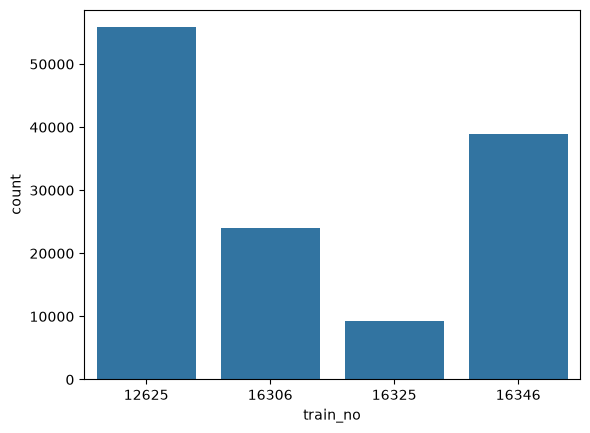

In [12]:
sns.countplot(data=df,x='train_no')

In [13]:
df['station_code'].value_counts()

station_code
AWY        4478
TCR        4353
KTU        2573
BDJ        2548
TIR        2533
           ... 
SMTL          1
KDTY          1
KFE           1
CWR           1
XX-TNAB       1
Name: count, Length: 132, dtype: int64

In [14]:
df['train_type'].value_counts()

train_type
MEX    72322
SUF    55801
Name: count, dtype: int64

<Axes: xlabel='train_type', ylabel='count'>

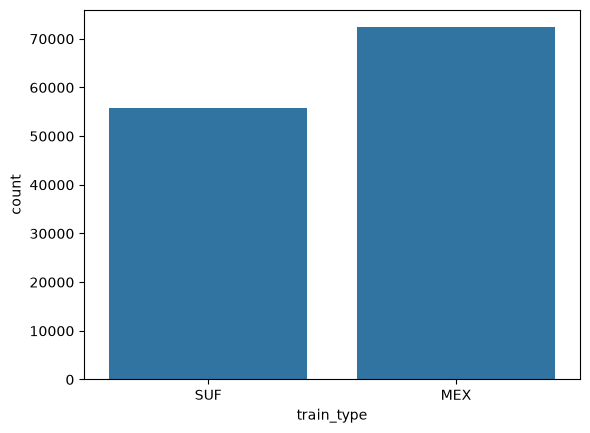

In [15]:
sns.countplot(data=df,x='train_type')

In [16]:
df['halts_here'].value_counts()

halts_here
1    128100
0        23
Name: count, dtype: int64

<Axes: xlabel='halts_here', ylabel='count'>

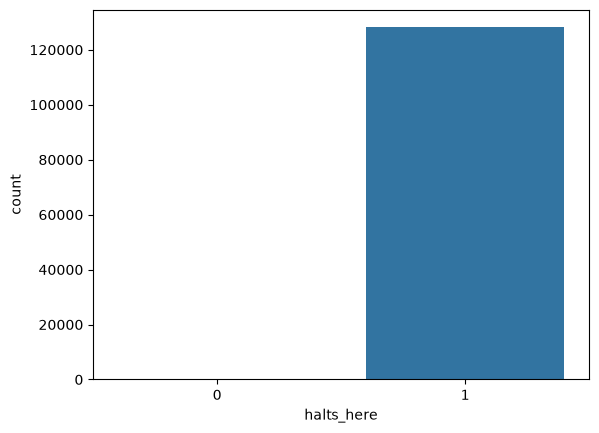

In [17]:
sns.countplot(data=df, x='halts_here')

In [18]:
df.isna().sum()

date                       0
train_no                   0
train_name                 0
train_type                 0
seq                        0
station_code               0
halts_here                 0
sch_arrival                0
sch_arrival_date           0
sch_departure              0
sch_departure_date         0
act_arrival                0
act_arrival_date           0
act_departure          10042
act_departure_date     10042
delay_arrival_min          0
delay_departure_min    10264
platform                1885
distance_km                0
lat                        0
lng                        0
departed                   0
reported                   0
reported_at                0
dtype: int64

In [19]:
df

,date,train_no,train_name,train_type,seq,station_code,halts_here,sch_arrival,sch_arrival_date,sch_departure,...,act_departure_date,delay_arrival_min,delay_departure_min,platform,distance_km,lat,lng,departed,reported,reported_at
1,2020-01-01,12625,KERALA SF EXP,SUF,11.0,VAK,1,11:49,01 Jan 2020,11:50,...,01 Jan 2020,16.0,22.0,1,40.468,8.737862,76.725536,1,1,2020-01-01T12:08:44.309807+05:30
2,2020-01-01,12625,KERALA SF EXP,SUF,17.0,QLN,1,12:22,01 Jan 2020,12:25,...,01 Jan 2020,8.0,17.0,2,64.206,8.884599,76.599089,1,1,2020-01-01T12:35:30.986416+05:30
3,2020-01-01,12625,KERALA SF EXP,SUF,23.0,KYJ,1,12:58,01 Jan 2020,13:00,...,01 Jan 2020,19.0,23.0,2,105.072,9.178853,76.513588,1,1,2020-01-01T13:19:06.401110+05:30
4,2020-01-01,12625,KERALA SF EXP,SUF,24.0,MVLK,1,13:09,01 Jan 2020,13:10,...,01 Jan 2020,21.0,28.0,1,112.878,9.237035,76.544363,1,1,2020-01-01T13:34:28.137609+05:30
5,2020-01-01,12625,KERALA SF EXP,SUF,26.0,CNGR,1,13:18,01 Jan 2020,13:20,...,01 Jan 2020,31.0,35.0,3,125.293,9.316419,76.607408,1,1,2020-01-01T13:50:13.252506+05:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173576,2026-08-31,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,168.0,KUDL,1,05:50,01 Sep 2026,05:52,...,01 Sep 2026,118.0,125.0,3.0,1031.386,16.018366,73.677655,1,1,2026-09-01T07:48:47.502731+05:30
173577,2026-08-31,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,175.0,RAJP,1,07:38,01 Sep 2026,07:40,...,01 Sep 2026,87.0,86.0,3.0,1106.880,16.633072,73.628476,1,1,2026-09-01T09:06:07.995195+05:30
173586,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,0.0,TVC,1,09:15,01 Sep 2026,09:15,...,01 Sep 2026,2.0,7.0,3.0,0.986,8.490026,76.943501,1,1,2026-09-01T09:17:07.588326+05:30
173587,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,11.0,VAK,1,09:51,01 Sep 2026,09:52,...,01 Sep 2026,6.0,11.0,1.0,40.412,8.737511,76.725847,1,1,2026-09-01T09:57:51.535711+05:30


# Drop Duplicated columns

In [20]:
sum(df.duplicated())

513

In [21]:
df.drop_duplicates(inplace=True)

In [22]:
df.columns

Index(['date', 'train_no', 'train_name', 'train_type', 'seq', 'station_code',
       'halts_here', 'sch_arrival', 'sch_arrival_date', 'sch_departure',
       'sch_departure_date', 'act_arrival', 'act_arrival_date',
       'act_departure', 'act_departure_date', 'delay_arrival_min',
       'delay_departure_min', 'platform', 'distance_km', 'lat', 'lng',
       'departed', 'reported', 'reported_at'],
      dtype='str')

# Drop unwanted Columns

In [23]:
df = df.drop(columns=['departed','reported', 'reported_at','act_departure', 'act_departure_date', 'lat', 'lng'])

In [24]:
sum(df.duplicated())

0

# Handle misiing Value

In [25]:
df.isna().sum()

date                       0
train_no                   0
train_name                 0
train_type                 0
seq                        0
station_code               0
halts_here                 0
sch_arrival                0
sch_arrival_date           0
sch_departure              0
sch_departure_date         0
act_arrival                0
act_arrival_date           0
delay_arrival_min          0
delay_departure_min    10237
platform                1885
distance_km                0
dtype: int64

In [26]:
df['delay_departure_min'] = df['delay_departure_min'].fillna(0)

In [27]:
df['delay_arrival_min'] = df['delay_arrival_min'].fillna(0)

In [28]:
df['platform'] = df['platform'].fillna(df['platform'].mode()[0])

In [29]:
df['halts_here'] = df['halts_here'].fillna(df['halts_here'].mode()[0])

In [30]:
# df = df.dropna()

In [31]:
df.isna().sum()

date                   0
train_no               0
train_name             0
train_type             0
seq                    0
station_code           0
halts_here             0
sch_arrival            0
sch_arrival_date       0
sch_departure          0
sch_departure_date     0
act_arrival            0
act_arrival_date       0
delay_arrival_min      0
delay_departure_min    0
platform               0
distance_km            0
dtype: int64

# Feature Engineering

In [32]:
df.columns

Index(['date', 'train_no', 'train_name', 'train_type', 'seq', 'station_code',
       'halts_here', 'sch_arrival', 'sch_arrival_date', 'sch_departure',
       'sch_departure_date', 'act_arrival', 'act_arrival_date',
       'delay_arrival_min', 'delay_departure_min', 'platform', 'distance_km'],
      dtype='str')

# Create delay Arraivel

## Sort df

In [33]:
df['date'] = pd.to_datetime(
    df['date'],
    format='mixed'
)

df = df.sort_values(
    ['train_no', 'date', 'seq']
).copy()



In [34]:
# Assumption: date identifies the journey's starting date.
journey = df.groupby(['train_no', 'date'])

## cretae previos delay

In [35]:


df['previous_delay'] = journey['delay_arrival_min'].shift(1)

df['previous_departure_delay'] = (
    journey['delay_departure_min'].shift(1)
)

df['previous_delay2'] = journey['delay_arrival_min'].shift(2)
df['previous_delay3'] = journey['delay_arrival_min'].shift(3)




In [36]:
df.isna().sum()

date                            0
train_no                        0
train_name                      0
train_type                      0
seq                             0
station_code                    0
halts_here                      0
sch_arrival                     0
sch_arrival_date                0
sch_departure                   0
sch_departure_date              0
act_arrival                     0
act_arrival_date                0
delay_arrival_min               0
delay_departure_min             0
platform                        0
distance_km                     0
previous_delay               4876
previous_departure_delay     4876
previous_delay2              9719
previous_delay3             14549
dtype: int64

## prev diff km

In [37]:
df['previous_distance_diff'] = journey['distance_km'].diff()

## last 3 stations delay avg

In [38]:
df['last_three_delay_avg'] = (
    journey['delay_arrival_min']
    .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
)


## station to station time difference

In [39]:
df['previous_sch_departure_date'] = journey['sch_departure'].shift(1)


previous_departure_minutes = pd.to_datetime(
    df['previous_sch_departure_date'],
    format='%H:%M',
    errors='coerce'
).dt.hour.mul(60).add(
    pd.to_datetime(
        df['previous_sch_departure_date'],
        format='%H:%M',
        errors='coerce'
    ).dt.minute
)

arrival_minutes = pd.to_datetime(
    df['sch_arrival'],
    format='%H:%M',
    errors='coerce'
).dt.hour.mul(60).add(
    pd.to_datetime(
        df['sch_arrival'],
        format='%H:%M',
        errors='coerce'
    ).dt.minute
)

# Add 24 hours when arrival occurs after midnight
difference = arrival_minutes - previous_departure_minutes
df['station_time_difference'] = difference.where(difference >= 0, difference + 1440)

In [40]:
df.isna().sum()

date                               0
train_no                           0
train_name                         0
train_type                         0
seq                                0
station_code                       0
halts_here                         0
sch_arrival                        0
sch_arrival_date                   0
sch_departure                      0
sch_departure_date                 0
act_arrival                        0
act_arrival_date                   0
delay_arrival_min                  0
delay_departure_min                0
platform                           0
distance_km                        0
previous_delay                  4876
previous_departure_delay        4876
previous_delay2                 9719
previous_delay3                14549
previous_distance_diff          4876
last_three_delay_avg            4876
previous_sch_departure_date     4876
station_time_difference         4876
dtype: int64

In [41]:
df.isna().sum()

date                               0
train_no                           0
train_name                         0
train_type                         0
seq                                0
station_code                       0
halts_here                         0
sch_arrival                        0
sch_arrival_date                   0
sch_departure                      0
sch_departure_date                 0
act_arrival                        0
act_arrival_date                   0
delay_arrival_min                  0
delay_departure_min                0
platform                           0
distance_km                        0
previous_delay                  4876
previous_departure_delay        4876
previous_delay2                 9719
previous_delay3                14549
previous_distance_diff          4876
last_three_delay_avg            4876
previous_sch_departure_date     4876
station_time_difference         4876
dtype: int64

# fill str/ num nulls

In [42]:
df['previous_sch_departure_date'] = df['previous_sch_departure_date'].astype(str)
df['station_time_difference']  = df['station_time_difference'].astype(str)

df['station_time_difference'] = df['station_time_difference'].fillna("0")
df['previous_sch_departure_date'] = df['previous_sch_departure_date'].fillna("0")


In [43]:
df.select_dtypes(include='number').fillna(0,inplace=True)

C:\Users\rehan\AppData\Local\Temp\ipykernel_5396\720608364.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df.select_dtypes(include='number').fillna(0,inplace=True)


,seq,halts_here,delay_arrival_min,delay_departure_min,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg
1,11.0,1,16.0,22.0,40.468,0.0,0.0,0.0,0.0,0.000,0.000000
2,17.0,1,8.0,17.0,64.206,16.0,22.0,0.0,0.0,23.738,16.000000
3,23.0,1,19.0,23.0,105.072,8.0,17.0,16.0,0.0,40.866,12.000000
4,24.0,1,21.0,28.0,112.878,19.0,23.0,8.0,16.0,7.806,14.333333
5,26.0,1,31.0,35.0,125.293,21.0,28.0,19.0,8.0,12.415,16.000000
...,...,...,...,...,...,...,...,...,...,...,...
173576,168.0,1,118.0,125.0,1031.386,118.0,121.0,115.0,49.0,50.810,94.000000
173577,175.0,1,87.0,86.0,1106.880,118.0,125.0,118.0,115.0,75.494,117.000000
173586,0.0,1,2.0,7.0,0.986,0.0,0.0,0.0,0.0,0.000,0.000000
173587,11.0,1,6.0,11.0,40.412,2.0,7.0,0.0,0.0,39.426,2.000000


In [44]:
df.fillna(0,inplace=True)

,date,train_no,train_name,train_type,seq,station_code,halts_here,sch_arrival,sch_arrival_date,sch_departure,...,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg,previous_sch_departure_date,station_time_difference
1,2020-01-01,12625,KERALA SF EXP,SUF,11.0,VAK,1,11:49,01 Jan 2020,11:50,...,1,40.468,0.0,0.0,0.0,0.0,0.000,0.000000,0,0
2,2020-01-01,12625,KERALA SF EXP,SUF,17.0,QLN,1,12:22,01 Jan 2020,12:25,...,2,64.206,16.0,22.0,0.0,0.0,23.738,16.000000,11:50,32.0
3,2020-01-01,12625,KERALA SF EXP,SUF,23.0,KYJ,1,12:58,01 Jan 2020,13:00,...,2,105.072,8.0,17.0,16.0,0.0,40.866,12.000000,12:25,33.0
4,2020-01-01,12625,KERALA SF EXP,SUF,24.0,MVLK,1,13:09,01 Jan 2020,13:10,...,1,112.878,19.0,23.0,8.0,16.0,7.806,14.333333,13:00,9.0
5,2020-01-01,12625,KERALA SF EXP,SUF,26.0,CNGR,1,13:18,01 Jan 2020,13:20,...,3,125.293,21.0,28.0,19.0,8.0,12.415,16.000000,13:10,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173576,2026-08-31,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,168.0,KUDL,1,05:50,01 Sep 2026,05:52,...,3.0,1031.386,118.0,121.0,115.0,49.0,50.810,94.000000,04:56,54.0
173577,2026-08-31,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,175.0,RAJP,1,07:38,01 Sep 2026,07:40,...,3.0,1106.880,118.0,125.0,118.0,115.0,75.494,117.000000,05:52,106.0
173586,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,0.0,TVC,1,09:15,01 Sep 2026,09:15,...,3.0,0.986,0.0,0.0,0.0,0.0,0.000,0.000000,0,0
173587,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,11.0,VAK,1,09:51,01 Sep 2026,09:52,...,1.0,40.412,2.0,7.0,0.0,0.0,39.426,2.000000,09:15,36.0


In [45]:
df.isna().sum()

date                           0
train_no                       0
train_name                     0
train_type                     0
seq                            0
station_code                   0
halts_here                     0
sch_arrival                    0
sch_arrival_date               0
sch_departure                  0
sch_departure_date             0
act_arrival                    0
act_arrival_date               0
delay_arrival_min              0
delay_departure_min            0
platform                       0
distance_km                    0
previous_delay                 0
previous_departure_delay       0
previous_delay2                0
previous_delay3                0
previous_distance_diff         0
last_three_delay_avg           0
previous_sch_departure_date    0
station_time_difference        0
dtype: int64

## Extract Day And Month

In [46]:
df['sch_arrival_date'] = pd.to_datetime(df['sch_arrival_date'], format='mixed')
df['weekend'] = df['sch_arrival_date'].dt.day_name().str[:3]

## Set Weekend

In [47]:
df['weekend']

1         Wed
2         Wed
3         Wed
4         Wed
5         Wed
         ... 
173576    Tue
173577    Tue
173586    Tue
173587    Tue
173589    Tue
Name: weekend, Length: 127610, dtype: str

In [48]:
df['weekend'].value_counts()

weekend
Mon    18592
Tue    18420
Wed    18327
Fri    18206
Thu    18152
Sun    18062
Sat    17851
Name: count, dtype: int64

In [49]:
df['is_weekend'] = df['weekend'].apply(lambda x: 1 if x in ['Sun','Sat'] else 0 )

In [50]:
df['is_weekend'].value_counts()

is_weekend
0    91697
1    35913
Name: count, dtype: int64

In [51]:
df['month'] = df['sch_arrival_date'].dt.month

In [52]:
df

,date,train_no,train_name,train_type,seq,station_code,halts_here,sch_arrival,sch_arrival_date,sch_departure,...,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg,previous_sch_departure_date,station_time_difference,weekend,is_weekend,month
1,2020-01-01,12625,KERALA SF EXP,SUF,11.0,VAK,1,11:49,2020-01-01,11:50,...,0.0,0.0,0.0,0.000,0.000000,0,0,Wed,0,1
2,2020-01-01,12625,KERALA SF EXP,SUF,17.0,QLN,1,12:22,2020-01-01,12:25,...,22.0,0.0,0.0,23.738,16.000000,11:50,32.0,Wed,0,1
3,2020-01-01,12625,KERALA SF EXP,SUF,23.0,KYJ,1,12:58,2020-01-01,13:00,...,17.0,16.0,0.0,40.866,12.000000,12:25,33.0,Wed,0,1
4,2020-01-01,12625,KERALA SF EXP,SUF,24.0,MVLK,1,13:09,2020-01-01,13:10,...,23.0,8.0,16.0,7.806,14.333333,13:00,9.0,Wed,0,1
5,2020-01-01,12625,KERALA SF EXP,SUF,26.0,CNGR,1,13:18,2020-01-01,13:20,...,28.0,19.0,8.0,12.415,16.000000,13:10,8.0,Wed,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173576,2026-08-31,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,168.0,KUDL,1,05:50,2026-09-01,05:52,...,121.0,115.0,49.0,50.810,94.000000,04:56,54.0,Tue,0,9
173577,2026-08-31,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,175.0,RAJP,1,07:38,2026-09-01,07:40,...,125.0,118.0,115.0,75.494,117.000000,05:52,106.0,Tue,0,9
173586,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,0.0,TVC,1,09:15,2026-09-01,09:15,...,0.0,0.0,0.0,0.000,0.000000,0,0,Tue,0,9
173587,2026-09-01,16346,Lokmanya Tilak Terminus NETHRAVATHI EXP,MEX,11.0,VAK,1,09:51,2026-09-01,09:52,...,7.0,0.0,0.0,39.426,2.000000,09:15,36.0,Tue,0,9


## extract hour

In [53]:
df['sch_arrival_hour'] = df['sch_arrival'].apply(lambda x: x.split(':')[0])


In [54]:
df['sch_arrival_hour']

1         11
2         12
3         12
4         13
5         13
          ..
173576    05
173577    07
173586    09
173587    09
173589    10
Name: sch_arrival_hour, Length: 127610, dtype: str

In [55]:
df['sch_arrival_hour'] = pd.to_numeric(df['sch_arrival_hour'])

In [56]:
df['sch_arrival_hour'] = pd.to_numeric(df['sch_arrival_hour'], errors='coerce')

def categorize_time(x):
    if pd.isna(x):
        return 'unknown'
    if 4 <= x <= 11:
        return 'morning'
    elif 12 <= x <= 15: # corrected logical interval for afternoon/noon
        return 'noon'
    elif 16 <= x <= 19: # corrected logical interval for evening
        return 'evening'
    else:
        return 'night'



# Change dtypes

In [57]:
df['train_no'] = df['train_no'].astype(str)
# df['seq'] = df['seq'].astype(str)

df['station_time_difference'] = pd.to_numeric(df['station_time_difference'])

# feature Selection

<Axes: >

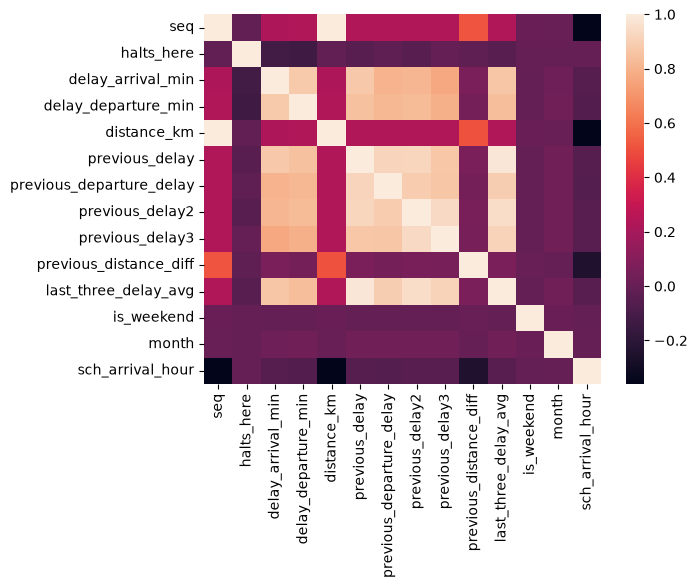

In [58]:
sns.heatmap(df.corr(numeric_only=True))

In [59]:
df.corr(numeric_only=True)

,seq,halts_here,delay_arrival_min,delay_departure_min,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg,is_weekend,month,sch_arrival_hour
seq,1.000000,-0.016177,0.223999,0.224902,0.997816,0.233394,0.227794,0.233133,0.228657,0.516097,0.227867,0.008340,0.005557,-0.358352
halts_here,-0.016177,1.000000,-0.119462,-0.132132,-0.016984,-0.048738,-0.022417,-0.050923,-0.003393,-0.022153,-0.048783,0.000614,0.000442,-0.003030
delay_arrival_min,0.223999,-0.119462,1.000000,0.881837,0.224163,0.876011,0.800376,0.811368,0.769144,0.063091,0.866151,-0.008186,0.026682,-0.055528
delay_departure_min,0.224902,-0.132132,0.881837,1.000000,0.224885,0.850839,0.814402,0.825298,0.789694,0.044590,0.839540,-0.007712,0.032994,-0.065822
distance_km,0.997816,-0.016984,0.224163,0.224885,1.000000,0.232598,0.227218,0.231698,0.226295,0.510410,0.226662,0.008487,0.005114,-0.359868
previous_delay,0.233394,-0.048738,0.876011,0.850839,0.232598,1.000000,0.916453,0.924005,0.868130,0.063786,0.982793,-0.008081,0.030431,-0.056276
previous_departure_delay,0.227794,-0.022417,0.800376,0.814402,0.227218,0.916453,1.000000,0.886791,0.863210,0.046523,0.892840,-0.008589,0.033148,-0.057151
previous_delay2,0.233133,-0.050923,0.811368,0.825298,0.231698,0.924005,0.886791,1.000000,0.936123,0.058178,0.947150,-0.008228,0.032569,-0.050750
previous_delay3,0.228657,-0.003393,0.769144,0.789694,0.226295,0.868130,0.863210,0.936123,1.000000,0.052317,0.909920,-0.008841,0.033562,-0.045486
previous_distance_diff,0.516097,-0.022153,0.063091,0.044590,0.510410,0.063786,0.046523,0.058178,0.052317,1.000000,0.062918,0.005510,-0.000573,-0.246271


# Drop Unwnated Columns

In [60]:
df.columns

Index(['date', 'train_no', 'train_name', 'train_type', 'seq', 'station_code',
       'halts_here', 'sch_arrival', 'sch_arrival_date', 'sch_departure',
       'sch_departure_date', 'act_arrival', 'act_arrival_date',
       'delay_arrival_min', 'delay_departure_min', 'platform', 'distance_km',
       'previous_delay', 'previous_departure_delay', 'previous_delay2',
       'previous_delay3', 'previous_distance_diff', 'last_three_delay_avg',
       'previous_sch_departure_date', 'station_time_difference', 'weekend',
       'is_weekend', 'month', 'sch_arrival_hour'],
      dtype='str')

In [61]:
df = df.drop(columns=['date','train_name','sch_arrival', 'sch_arrival_date', 'sch_departure',
       'sch_departure_date', 'act_arrival', 'act_arrival_date',
       'act_departure', 'act_departure_date','lat', 'lng','reported', 'reported_at','Unnamed: 0','weekend','halts_here'], errors='ignore')

In [62]:
df.isna().sum()

train_no                       0
train_type                     0
seq                            0
station_code                   0
delay_arrival_min              0
delay_departure_min            0
platform                       0
distance_km                    0
previous_delay                 0
previous_departure_delay       0
previous_delay2                0
previous_delay3                0
previous_distance_diff         0
last_three_delay_avg           0
previous_sch_departure_date    0
station_time_difference        0
is_weekend                     0
month                          0
sch_arrival_hour               0
dtype: int64

# Handle Category columns

In [63]:
cat_col = df.select_dtypes('object')

C:\Users\rehan\AppData\Local\Temp\ipykernel_5396\1846162425.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = df.select_dtypes('object')


In [64]:
for col in cat_col:
  print(df[col].value_counts())
  print('*'*100)

train_no
12625    55586
16346    38826
16306    23992
16325     9206
Name: count, dtype: int64
****************************************************************************************************
train_type
MEX    72024
SUF    55586
Name: count, dtype: int64
****************************************************************************************************
station_code
AWY        4461
TCR        4337
KTU        2563
BDJ        2538
TIR        2522
           ... 
SMTL          1
KDTY          1
KFE           1
CWR           1
XX-TNAB       1
Name: count, Length: 132, dtype: int64
****************************************************************************************************
platform
1.0     42841
2       20251
2.0     18156
1       15135
3        9581
3.0      7705
4        5969
5        2539
5.0      1197
4.0      1116
6.0       736
8.0       728
7.0       634
10        364
7         241
9         181
6         173
8          25
02         14
२          10
9.0         4
22.0    

# handle Platform

In [65]:
df["platform"] = df["platform"].astype("string").str.strip().str.upper()

In [66]:
df["platform"] = df["platform"].str.translate(
    str.maketrans("०१२३४५६७८९", "0123456789")
)

In [67]:
# Remove .0 from numeric values
df["platform"] = df["platform"].str.replace(
    r"^(\d+)\.0$", r"\1", regex=True
)

In [68]:
df.loc[df['platform'] == '3A']

,train_no,train_type,seq,station_code,delay_arrival_min,delay_departure_min,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg,previous_sch_departure_date,station_time_difference,is_weekend,month,sch_arrival_hour


In [69]:
df.loc[df['platform'] == '1A']

,train_no,train_type,seq,station_code,delay_arrival_min,delay_departure_min,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg,previous_sch_departure_date,station_time_difference,is_weekend,month,sch_arrival_hour


in this two platformm doesnt have 1A or 3A so it change 1 and 3

In [70]:
df['platform'] = df['platform'].replace({'1A': '1', '3A': '3'})

In [71]:
df['platform'] = pd.to_numeric(df['platform'])

# Handle Ouliers

In [72]:
df.select_dtypes(include='number')

,seq,delay_arrival_min,delay_departure_min,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg,is_weekend,month,sch_arrival_hour
1,11.0,16.0,22.0,1,40.468,0.0,0.0,0.0,0.0,0.000,0.000000,0,1,11
2,17.0,8.0,17.0,2,64.206,16.0,22.0,0.0,0.0,23.738,16.000000,0,1,12
3,23.0,19.0,23.0,2,105.072,8.0,17.0,16.0,0.0,40.866,12.000000,0,1,12
4,24.0,21.0,28.0,1,112.878,19.0,23.0,8.0,16.0,7.806,14.333333,0,1,13
5,26.0,31.0,35.0,3,125.293,21.0,28.0,19.0,8.0,12.415,16.000000,0,1,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173576,168.0,118.0,125.0,3,1031.386,118.0,121.0,115.0,49.0,50.810,94.000000,0,9,5
173577,175.0,87.0,86.0,3,1106.880,118.0,125.0,118.0,115.0,75.494,117.000000,0,9,7
173586,0.0,2.0,7.0,3,0.986,0.0,0.0,0.0,0.0,0.000,0.000000,0,9,9
173587,11.0,6.0,11.0,1,40.412,2.0,7.0,0.0,0.0,39.426,2.000000,0,9,9


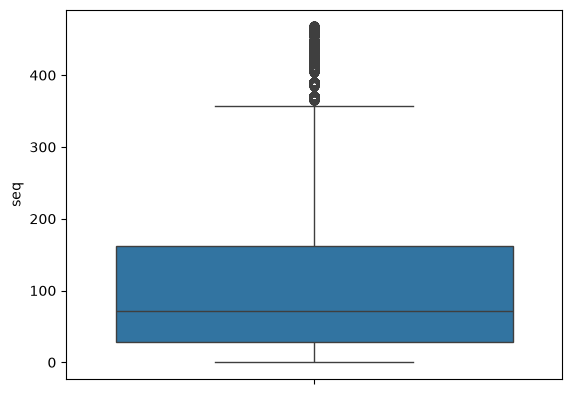

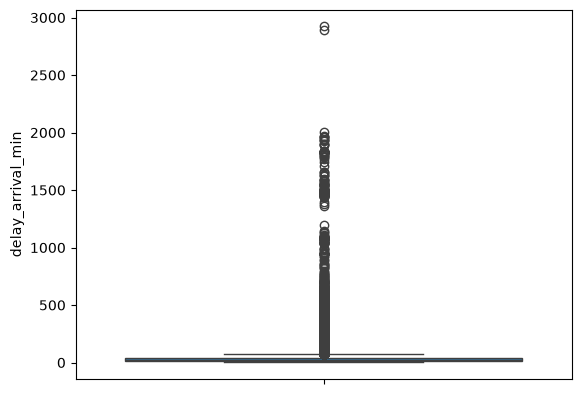

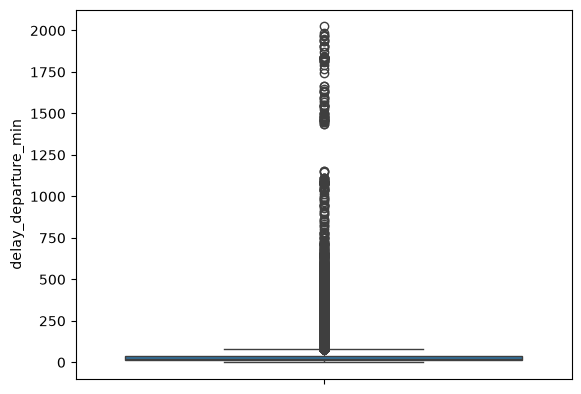

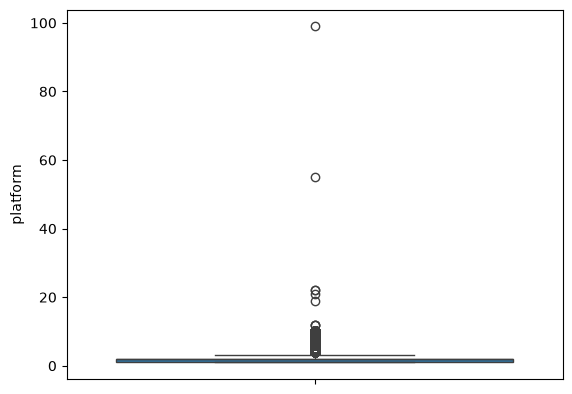

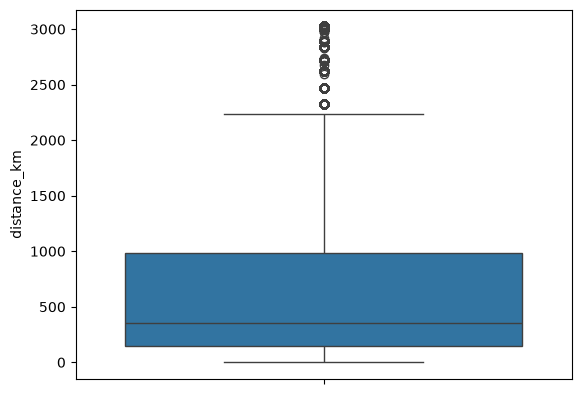

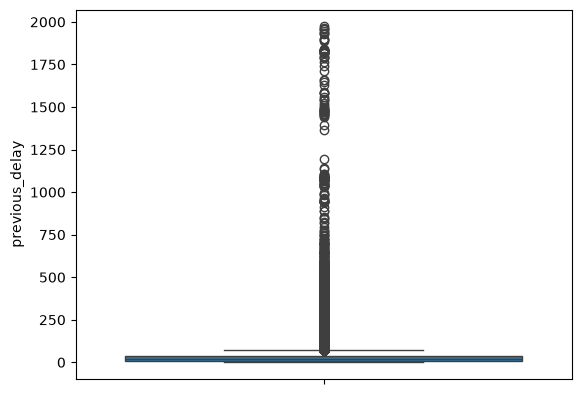

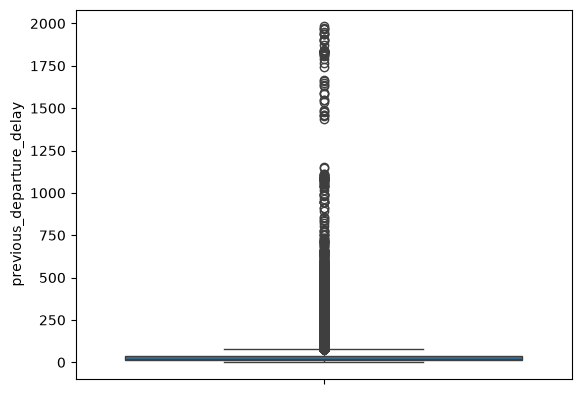

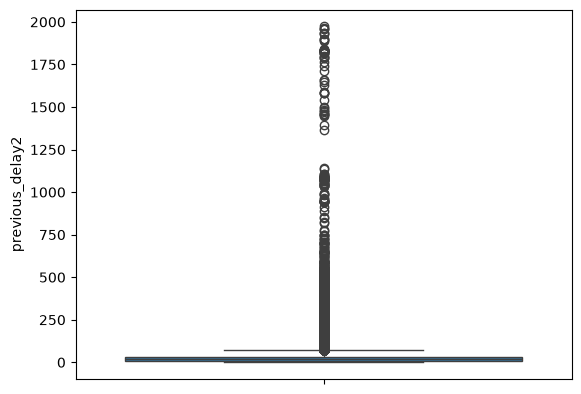

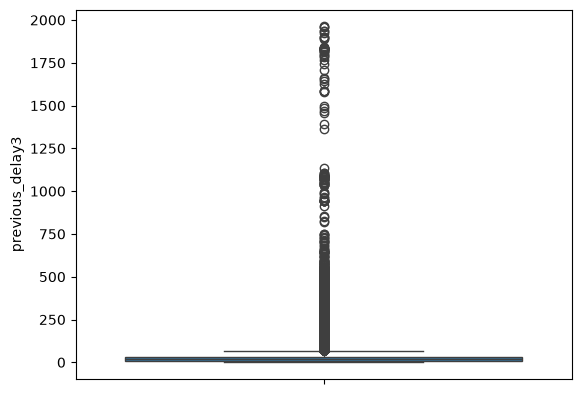

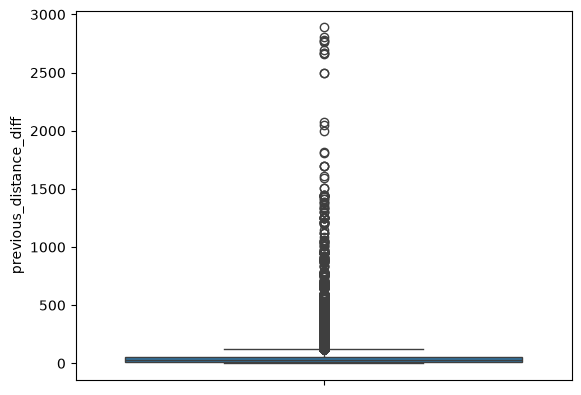

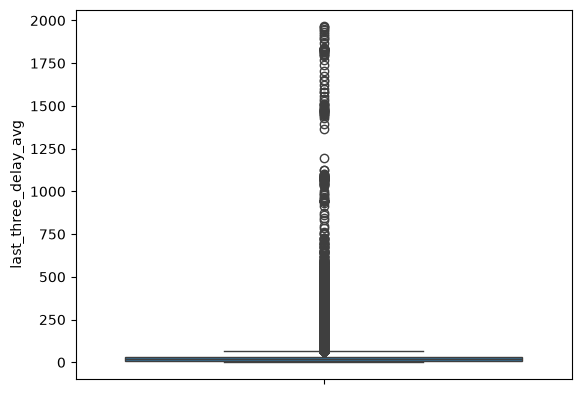

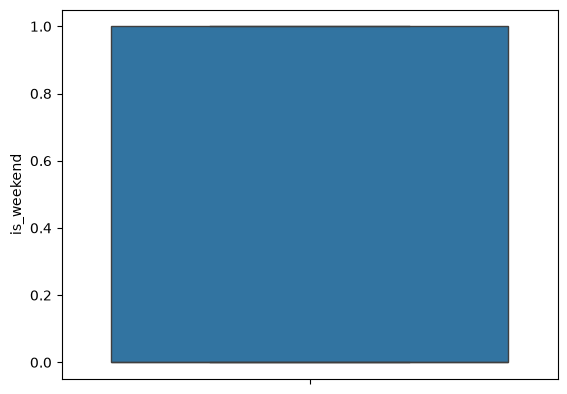

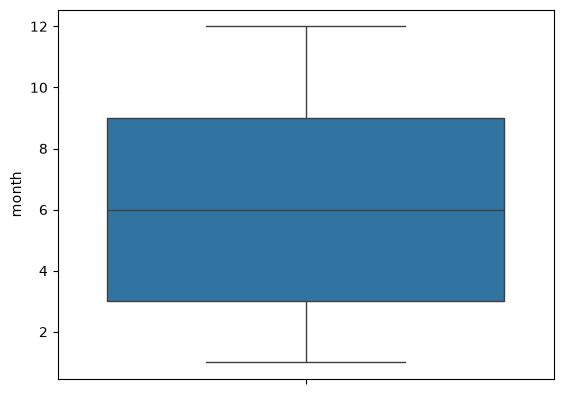

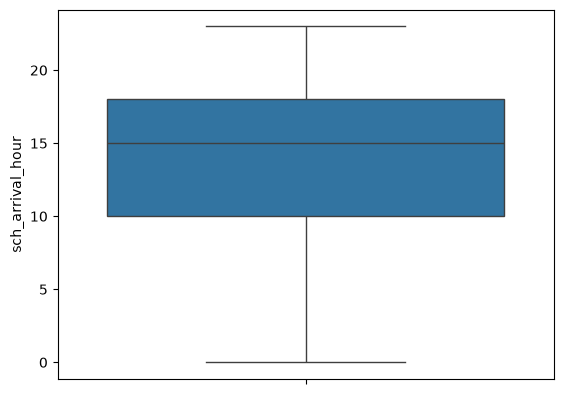

In [73]:
for i in df.select_dtypes(include='number'):
  sns.boxplot(data=df,y=i)
  plt.show()

In [74]:
# df.loc[df["seq"] >350,'seq'] = df['seq'].median()

In [75]:
df.loc[df['platform'] > 10, 'platform' ] = df['platform'].mode()[0]

In [76]:
df

,train_no,train_type,seq,station_code,delay_arrival_min,delay_departure_min,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg,previous_sch_departure_date,station_time_difference,is_weekend,month,sch_arrival_hour
1,12625,SUF,11.0,VAK,16.0,22.0,1,40.468,0.0,0.0,0.0,0.0,0.000,0.000000,0,0,0,1,11
2,12625,SUF,17.0,QLN,8.0,17.0,2,64.206,16.0,22.0,0.0,0.0,23.738,16.000000,11:50,32.0,0,1,12
3,12625,SUF,23.0,KYJ,19.0,23.0,2,105.072,8.0,17.0,16.0,0.0,40.866,12.000000,12:25,33.0,0,1,12
4,12625,SUF,24.0,MVLK,21.0,28.0,1,112.878,19.0,23.0,8.0,16.0,7.806,14.333333,13:00,9.0,0,1,13
5,12625,SUF,26.0,CNGR,31.0,35.0,3,125.293,21.0,28.0,19.0,8.0,12.415,16.000000,13:10,8.0,0,1,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173576,16346,MEX,168.0,KUDL,118.0,125.0,3,1031.386,118.0,121.0,115.0,49.0,50.810,94.000000,04:56,54.0,0,9,5
173577,16346,MEX,175.0,RAJP,87.0,86.0,3,1106.880,118.0,125.0,118.0,115.0,75.494,117.000000,05:52,106.0,0,9,7
173586,16346,MEX,0.0,TVC,2.0,7.0,3,0.986,0.0,0.0,0.0,0.0,0.000,0.000000,0,0,0,9,9
173587,16346,MEX,11.0,VAK,6.0,11.0,1,40.412,2.0,7.0,0.0,0.0,39.426,2.000000,09:15,36.0,0,9,9


# Regression Plot

<Axes: xlabel='delay_arrival_min', ylabel='previous_delay'>

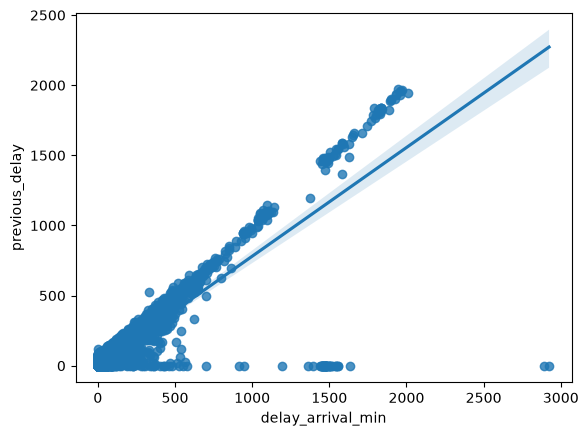

In [77]:
sns.regplot(data=df,y='previous_delay',x='delay_arrival_min')

In [78]:
# sns.pairplot(data=df)

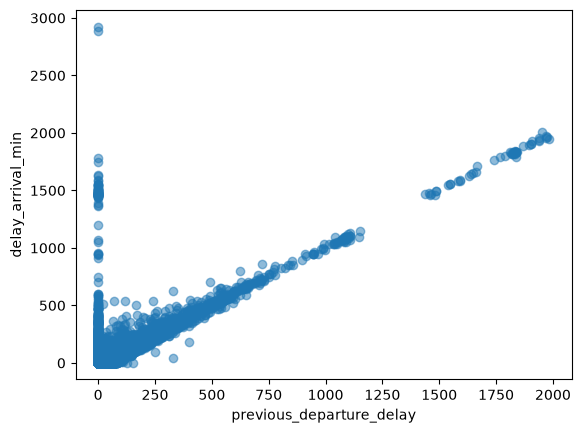

In [79]:
plt.plot(df['previous_departure_delay'], df['delay_arrival_min'], 'o', alpha=0.5)
plt.xlabel('previous_departure_delay')
plt.ylabel('delay_arrival_min')
plt.show()

 # split x and y

In [80]:
df.columns

Index(['train_no', 'train_type', 'seq', 'station_code', 'delay_arrival_min',
       'delay_departure_min', 'platform', 'distance_km', 'previous_delay',
       'previous_departure_delay', 'previous_delay2', 'previous_delay3',
       'previous_distance_diff', 'last_three_delay_avg',
       'previous_sch_departure_date', 'station_time_difference', 'is_weekend',
       'month', 'sch_arrival_hour'],
      dtype='str')

In [81]:
x = df.drop(columns=['delay_arrival_min','departed','delay_departure_min','weekend','previous_sch_departure_date'], errors='ignore')


In [82]:
df.isna().sum()

train_no                       0
train_type                     0
seq                            0
station_code                   0
delay_arrival_min              0
delay_departure_min            0
platform                       0
distance_km                    0
previous_delay                 0
previous_departure_delay       0
previous_delay2                0
previous_delay3                0
previous_distance_diff         0
last_three_delay_avg           0
previous_sch_departure_date    0
station_time_difference        0
is_weekend                     0
month                          0
sch_arrival_hour               0
dtype: int64

In [83]:
x

,train_no,train_type,seq,station_code,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,last_three_delay_avg,station_time_difference,is_weekend,month,sch_arrival_hour
1,12625,SUF,11.0,VAK,1,40.468,0.0,0.0,0.0,0.0,0.000,0.000000,0,0,1,11
2,12625,SUF,17.0,QLN,2,64.206,16.0,22.0,0.0,0.0,23.738,16.000000,32.0,0,1,12
3,12625,SUF,23.0,KYJ,2,105.072,8.0,17.0,16.0,0.0,40.866,12.000000,33.0,0,1,12
4,12625,SUF,24.0,MVLK,1,112.878,19.0,23.0,8.0,16.0,7.806,14.333333,9.0,0,1,13
5,12625,SUF,26.0,CNGR,3,125.293,21.0,28.0,19.0,8.0,12.415,16.000000,8.0,0,1,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173576,16346,MEX,168.0,KUDL,3,1031.386,118.0,121.0,115.0,49.0,50.810,94.000000,54.0,0,9,5
173577,16346,MEX,175.0,RAJP,3,1106.880,118.0,125.0,118.0,115.0,75.494,117.000000,106.0,0,9,7
173586,16346,MEX,0.0,TVC,3,0.986,0.0,0.0,0.0,0.0,0.000,0.000000,0,0,9,9
173587,16346,MEX,11.0,VAK,1,40.412,2.0,7.0,0.0,0.0,39.426,2.000000,36.0,0,9,9


In [84]:
sum(x.isna().sum())

0

In [85]:
y = df['delay_arrival_min']

In [86]:
# df['seq'] = df['seq'].astype(str)

In [87]:
# df['platform'] = df['platform'].astype(str)

In [88]:
x.info()

<class 'pandas.DataFrame'>
Index: 127610 entries, 1 to 173589
Data columns (total 16 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   train_no                  127610 non-null  str    
 1   train_type                127610 non-null  str    
 2   seq                       127610 non-null  float64
 3   station_code              127610 non-null  str    
 4   platform                  127610 non-null  Int64  
 5   distance_km               127610 non-null  float64
 6   previous_delay            127610 non-null  float64
 7   previous_departure_delay  127610 non-null  float64
 8   previous_delay2           127610 non-null  float64
 9   previous_delay3           127610 non-null  float64
 10  previous_distance_diff    127610 non-null  float64
 11  last_three_delay_avg      127610 non-null  float64
 12  station_time_difference   127610 non-null  str    
 13  is_weekend                127610 non-null  int64  
 14  mont

# Encode

In [89]:
from sklearn.preprocessing import LabelEncoder

In [90]:
lab = LabelEncoder()


In [91]:
cat_col = x.select_dtypes('object')
cat_col = cat_col.drop(columns=['station_code'])

C:\Users\rehan\AppData\Local\Temp\ipykernel_5396\4122507570.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = x.select_dtypes('object')


In [92]:

for i in cat_col:
    x[i] = lab.fit_transform(x[i])

In [93]:
x = pd.get_dummies(x,dtype=int,drop_first=True)

In [94]:
x

,train_no,train_type,seq,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,...,station_code_VARD,station_code_VGLB,station_code_VGLJ,station_code_VNB,station_code_VPZ,station_code_VTK,station_code_VVH,station_code_WKI,station_code_WL,station_code_XX-TNAB
1,0,1,11.0,1,40.468,0.0,0.0,0.0,0.0,0.000,...,0,0,0,0,0,0,0,0,0,0
2,0,1,17.0,2,64.206,16.0,22.0,0.0,0.0,23.738,...,0,0,0,0,0,0,0,0,0,0
3,0,1,23.0,2,105.072,8.0,17.0,16.0,0.0,40.866,...,0,0,0,0,0,0,0,0,0,0
4,0,1,24.0,1,112.878,19.0,23.0,8.0,16.0,7.806,...,0,0,0,0,0,0,0,0,0,0
5,0,1,26.0,3,125.293,21.0,28.0,19.0,8.0,12.415,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173576,3,0,168.0,3,1031.386,118.0,121.0,115.0,49.0,50.810,...,0,0,0,0,0,0,0,0,0,0
173577,3,0,175.0,3,1106.880,118.0,125.0,118.0,115.0,75.494,...,0,0,0,0,0,0,0,0,0,0
173586,3,0,0.0,3,0.986,0.0,0.0,0.0,0.0,0.000,...,0,0,0,0,0,0,0,0,0,0
173587,3,0,11.0,1,40.412,2.0,7.0,0.0,0.0,39.426,...,0,0,0,0,0,0,0,0,0,0


# Ml Building

train test split

In [95]:
from sklearn.model_selection import train_test_split

In [96]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.2,random_state=42)

# Linear Regression

In [97]:
from sklearn.linear_model import LinearRegression

In [98]:
model = LinearRegression(copy_X= True, fit_intercept=True, n_jobs= -1)
model.fit(x_train,y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](146,)","[-0.58,-0.4 ,-0.54,..., 7.25,22.44,54.57]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](146,)","['train_no','train_type','seq',...,'station_code_WKI','station_code_WL', 'station_code_XX-TNAB']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.917
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,146
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(146)


In [99]:
y_pred = model.predict(x_test)

In [100]:
y_pred

array([53.63032704, 19.91253464, 21.90836669, ..., 18.42391876,
       39.61541327, 36.86742713], shape=(25522,))

In [101]:
from sklearn.metrics import r2_score,mean_absolute_percentage_error,mean_absolute_error,mean_squared_error

In [102]:
r2 = r2_score(y_test,y_pred)
mape = mean_absolute_percentage_error(y_test,y_pred)

In [103]:
print(r2)

0.8034513203041673


In [104]:
print(mape)

0.5638352065226494


# Random Forest

In [105]:
from sklearn.ensemble import RandomForestRegressor

In [106]:
model2 = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=20, min_samples_leaf=1, min_samples_split=2)
model2.fit(x_train,y_train)
y_pred2 = model2.predict(x_test)


In [107]:
r2_score(y_test,y_pred2)

0.8399039090080751

In [108]:
mean_absolute_percentage_error(y_test,y_pred2)

0.46404072616144937

In [109]:
mean_absolute_error(y_test,y_pred2)

6.270883390356704

# Cross Validation

In [110]:
#linear regression model

In [111]:
from sklearn.model_selection import cross_val_score

In [112]:
cross_val = cross_val_score(model,x,y,cv=3)
print(cross_val.mean())

0.5603316974792653


In [113]:
#random forest model

In [114]:
cross_val2 = cross_val_score(model2,x,y,cv=5)
print(cross_val2.mean())

0.1514945568168348


# Hyper Parameter Tuning

In [115]:
x_train

,train_no,train_type,seq,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,previous_distance_diff,...,station_code_VARD,station_code_VGLB,station_code_VGLJ,station_code_VNB,station_code_VPZ,station_code_VTK,station_code_VVH,station_code_WKI,station_code_WL,station_code_XX-TNAB
96087,1,0,45.0,2,232.012,31.0,33.0,29.0,38.0,24.030,...,0,0,0,0,0,0,0,0,0,0
107926,1,0,6.0,2,29.626,6.0,6.0,0.0,0.0,9.018,...,0,0,0,0,0,0,0,0,0,0
74698,0,1,11.0,1,40.624,0.0,0.0,0.0,0.0,0.000,...,0,0,0,0,0,0,0,0,0,0
78989,1,0,25.0,3,121.861,37.0,42.0,32.0,24.0,7.961,...,0,0,0,0,0,0,0,0,0,0
58547,0,1,24.0,2,113.218,16.0,21.0,11.0,7.0,8.080,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
164400,3,0,71.0,1,342.808,33.0,36.0,31.0,26.0,62.844,...,0,0,0,0,0,0,0,0,0,0
144040,3,0,21.0,1,91.313,4.0,9.0,0.0,0.0,50.798,...,0,0,0,0,0,0,0,0,0,0
1583,0,1,30.0,1,160.129,13.0,16.0,18.0,13.0,17.751,...,0,0,0,0,0,0,0,0,0,0
22335,0,1,88.0,2,473.483,15.0,29.0,24.0,21.0,50.757,...,0,0,0,0,0,0,0,0,0,0


In [116]:
from sklearn.model_selection import GridSearchCV

In [117]:
model0 = RandomForestRegressor()


In [118]:
# Redefine the parameters as a dictionary of lists for the grid search
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 3]
}

grid = GridSearchCV(
    estimator=model0,
    param_grid=param_grid,
    cv=3,       # reduced cv from 5 to 3 for faster run times on large datasets
    scoring='r2',
    n_jobs=-1
)

grid.fit(x_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV R2 Score:", grid.best_score_)

KeyboardInterrupt: 

In [ ]:
# Linear Regression Grid Search

In [ ]:
model00= LinearRegression()

In [ ]:
param_grid_linear = {
    "fit_intercept": [True, False],
    "copy_X": [True, False],
    "n_jobs": [-1, 1],
    "positive":[True,False]


}

In [ ]:


grid = GridSearchCV(
    estimator=model00,
    param_grid=param_grid_linear,
    cv=3,       # reduced cv from 5 to 3 for faster run times on large datasets
    scoring='r2',
    n_jobs=-1
)

grid.fit(x_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV R2 Score:", grid.best_score_)

In [ ]:
data = pd.DataFrame(
    {
        'actual':y_test,
        'predicted_linear':y_pred,
        'difference_linear':y_test-y_pred,
        'predicted_forst':y_pred2,
        'difference_forst':y_test-y_pred2
    }
)

In [ ]:
data

In [ ]:
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

model = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.8528084792186185
MAE: 6.298662946515573
RMSE: 25.86372979616456


In [ ]:
cross_val2 = cross_val_score(model,x,y,cv=5)
print(cross_val2.mean())

0.6992813983099251


In [ ]:
import joblib
joblib.dump(model2,'model.pkl')

['model.pkl']

In [ ]:
# Assign predictions to the corresponding test-set rows
x["prediction"] = pd.NA
x.loc[y_test.index, "prediction"] = y_pred2

In [ ]:
x['delay_prediction'] = df['delay_arrival_min']

In [ ]:
x

,train_no,train_type,seq,halts_here,platform,distance_km,previous_delay,previous_departure_delay,previous_delay2,previous_delay3,...,station_code_VGLJ,station_code_VNB,station_code_VPZ,station_code_VTK,station_code_VVH,station_code_WKI,station_code_WL,station_code_XX-TNAB,prediction,delay_prediction
1,0,1,11.0,1,1,40.468,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,12.055581,16.0
2,0,1,17.0,1,2,64.206,16.0,22.0,0.0,0.0,...,0,0,0,0,0,0,0,0,<NA>,8.0
3,0,1,23.0,1,2,105.072,8.0,17.0,16.0,0.0,...,0,0,0,0,0,0,0,0,<NA>,19.0
4,0,1,24.0,1,1,112.878,19.0,23.0,8.0,16.0,...,0,0,0,0,0,0,0,0,21.992153,21.0
5,0,1,26.0,1,3,125.293,21.0,28.0,19.0,8.0,...,0,0,0,0,0,0,0,0,<NA>,31.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173576,3,0,168.0,1,3,1031.386,118.0,121.0,115.0,49.0,...,0,0,0,0,0,0,0,0,<NA>,118.0
173577,3,0,175.0,1,3,1106.880,118.0,125.0,118.0,115.0,...,0,0,0,0,0,0,0,0,<NA>,87.0
173586,3,0,0.0,1,3,0.986,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,<NA>,2.0
173587,3,0,11.0,1,1,40.412,2.0,7.0,0.0,0.0,...,0,0,0,0,0,0,0,0,14.198624,6.0


In [ ]:
x.dropna(inplace=True)

In [ ]:
x['delay_arrival_min'] = pd.to_numeric(
    y.reindex(x.index),
    errors='coerce'
)

In [ ]:
x['diff'] = x['delay_arrival_min'] - x['prediction']

In [ ]:
x['diff'] =x['diff'].abs()

In [ ]:
j =x.groupby(by='train_no')['train_no']
j

In [ ]:
j = x.groupby("train_no")["diff"]

In [ ]:
j.max()

,diff
train_no,
0,1371.335424
1,1454.106855
2,80.292224
3,1557.725287


In [ ]:
j.min()

,diff
train_no,
0,0.000399
1,0.000294
2,0.001875
3,0.001099


In [ ]:
j.mean()

,diff
train_no,
0,7.614628
1,3.778368
2,2.069638
3,6.83064


In [ ]:
mean_absolute_error(y_test,y_pred2)

6.257108134224666

<Axes: xlabel='train_no', ylabel='diff'>

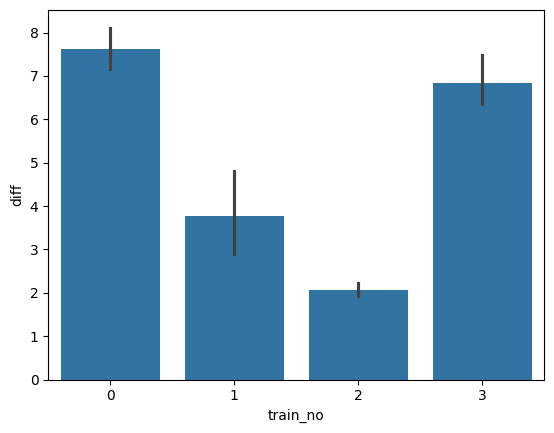

In [ ]:
sns.barplot(data=x,x=x['train_no'],y=x['diff'])

<Axes: xlabel='train_no', ylabel='count'>

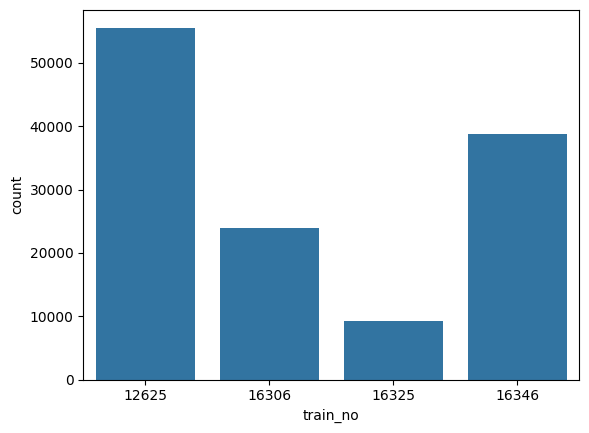

In [ ]:
sns.countplot(data=df,x='train_no')

<Axes: xlabel='train_no', ylabel='count'>

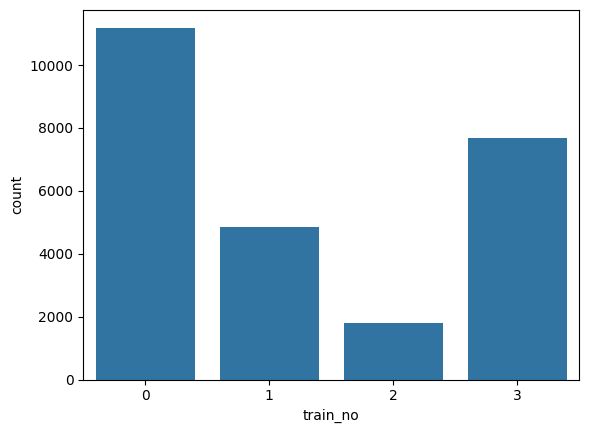

In [ ]:
sns.countplot(data=x,x='train_no')